<a href="https://colab.research.google.com/github/leeknnn/viktoriiashkorubska-41/blob/master/lab_work_22/lab_work_22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

--- Перші 12 місяців ряду ---
2015-01-01    -2.9
2015-02-01    -3.2
2015-03-01     2.0
2015-04-01     8.4
2015-05-01    17.4
2015-06-01    19.3
2015-07-01    25.3
2015-08-01    20.9
2015-09-01    16.8
2015-10-01     9.3
2015-11-01     4.0
2015-12-01    -4.6
Freq: MS, Name: температура, dtype: float64

--- Завдання 2: Ковзне середнє ---


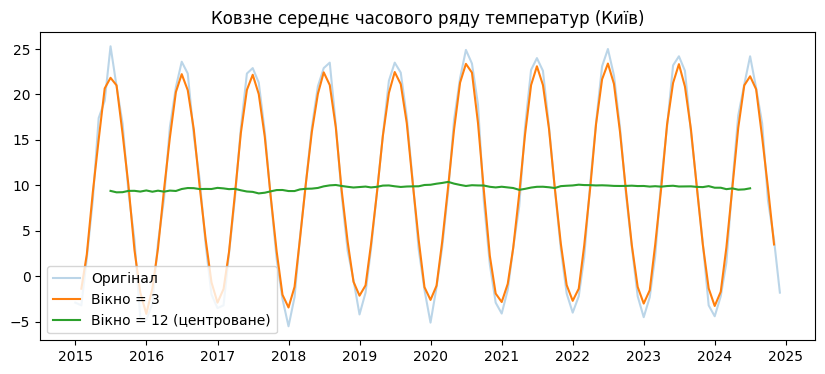


--- Завдання 3: Декомпозиція ---
Стандартне відхилення залишку (resid): 0.79

--- Завдання 4: Прогноз на 12 місяців уперед ---
Прогноз на 12 місяців:
2025-01-01    -4.2
2025-02-01    -1.9
2025-03-01     3.1
2025-04-01     9.7
2025-05-01    16.9
2025-06-01    22.2
2025-07-01    24.3
2025-08-01    22.7
2025-09-01    17.0
2025-10-01     9.8
2025-11-01     3.2
2025-12-01    -2.0
Freq: MS, dtype: float64

--- Завдання 5: Перевірка статистичної значущості тренду ---
Нахил = 0.0473 °C/рік
Stderr = 0.0274
p-value = 8.7349e-02
95% довірчий інтервал для нахилу: (-0.0065, 0.1010)


In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
from scipy.stats import linregress

# Варіант 1: Київ (base_temp = 9.5, amplitude = 14, trend_per_year = 0.04, noise_scale = 1.0)
np.random.seed(1)
base_temp = 9.5
amplitude = 14
trend_per_year = 0.04
noise_scale = 1.0
city = "Київ"
n_years = 10

dates = pd.date_range(start="2015-01-01", periods=n_years * 12, freq="MS")
month = dates.month
years_elapsed = (dates.year - dates.year[0]) + (dates.month - 1) / 12
seasonal = amplitude * np.cos((month - 7) / 12 * 2 * np.pi)
trend = trend_per_year * years_elapsed
noise = np.random.normal(0, noise_scale, len(dates))
temp = np.round(base_temp + trend + seasonal + noise, 1)

climate_ts = pd.Series(temp, index=dates, name="температура")

print("--- Перші 12 місяців ряду ---")
print(climate_ts.head(12))

print("\n--- Завдання 2: Ковзне середнє ---")
ma3 = climate_ts.rolling(window=3, center=True).mean()
ma12 = climate_ts.rolling(window=12, center=True).mean()
ma12_trailing = climate_ts.rolling(window=12, center=False).mean()

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(climate_ts.index, climate_ts.values, alpha=0.3, label="Оригінал")
ax.plot(climate_ts.index, ma3.values, label="Вікно = 3")
ax.plot(climate_ts.index, ma12.values, label="Вікно = 12 (центроване)")
ax.legend()
ax.set_title("Ковзне середнє часового ряду температур (Київ)")
plt.show()

print("\n--- Завдання 3: Декомпозиція ---")
decomposition = seasonal_decompose(climate_ts, model="additive", period=12)
print("Стандартне відхилення залишку (resid):", round(decomposition.resid.dropna().std(), 2))

print("\n--- Завдання 4: Прогноз на 12 місяців уперед ---")
t = np.arange(len(climate_ts))
known = decomposition.trend.notna().values
fit = linregress(t[known], decomposition.trend[known])

n_ahead = 12
t_future = np.arange(len(climate_ts), len(climate_ts) + n_ahead)
trend_forecast = fit.intercept + fit.slope * t_future
seasonal_by_month = decomposition.seasonal.groupby(decomposition.seasonal.index.month).mean()
future_dates = pd.date_range(climate_ts.index[-1] + pd.offsets.MonthBegin(1), periods=n_ahead, freq="MS")
seasonal_forecast = seasonal_by_month.reindex(future_dates.month).values
forecast = pd.Series(trend_forecast + seasonal_forecast, index=future_dates)
print("Прогноз на 12 місяців:")
print(forecast.round(1))

print("\n--- Завдання 5: Перевірка статистичної значущості тренду ---")
deseason = climate_ts - decomposition.seasonal
t_years = np.arange(len(climate_ts)) / 12
trend_test = linregress(t_years, deseason.values)

print(f"Нахил = {trend_test.slope:.4f} °C/рік")
print(f"Stderr = {trend_test.stderr:.4f}")
print(f"p-value = {trend_test.pvalue:.4e}")

ci_low = trend_test.slope - 1.96 * trend_test.stderr
ci_high = trend_test.slope + 1.96 * trend_test.stderr
print(f"95% довірчий інтервал для нахилу: ({ci_low:.4f}, {ci_high:.4f})")

## Відповіді на контрольні питання

1. **Чому часовий ряд не можна аналізувати тими самими методами, що звичайну незалежну вибірку?**
   - Елементи часового ряду хронологично впорядковані та зазвичай демонструють сильну автокореляцію (сусідні спостереження пов'язані між собою через тренди та сезонність), що порушує базову вимогу класичної статистики про незалежність та однакову розподіленість вибіркових спостережень (i.i.d.).

2. **Чому надто мале й надто велике вікно ковзного середнього є проблемою?**
   - Занадто мале вікно погано згладжує випадковий шум, залишаючи коливання. Занадто велике вікно розмиває локальні зміни та структуру. Розмір вікна слід узгоджувати з періодом сезонності (наприклад, вікно 12 для місячних даних), щоб повний сезонний цикл взаємно компенсувався.

3. **У чому різниця між трейлінговим і центрованим ковзним середнім?**
   - Трейлінгове ковзне середнє обчислюється за попередніми точками і має помітний часовий зсув (лаг) на графіку. Центроване середнє розраховується симетрично навколо поточного моменту, усуваючи лаг, але вимагає «даних з майбутнього», через що недоступне в задачах прогнозування в реальному часі.

4. **Чому саме p-value нахилу тренду визначає статистичну значущість?**
   - Сам факт додатного нахилу (`slope > 0`) може бути наслідком випадкового шуму на короткій чи обмеженій вибірці. Значення `p-value` перевіряє нульову гіпотезу про те, що справжній нахил дорівнює нулю, і лише достатньо мале `p-value` ($p < 0.05$) підтверджує, що виявлена тенденція є статистично значущою, а не випадковою флуктуацією.